# Activity 7.06 - Education, Salary, and Weekly Hours

In [1]:
%pip install squarify

Note: you may need to restart the kernel to use updated packages.


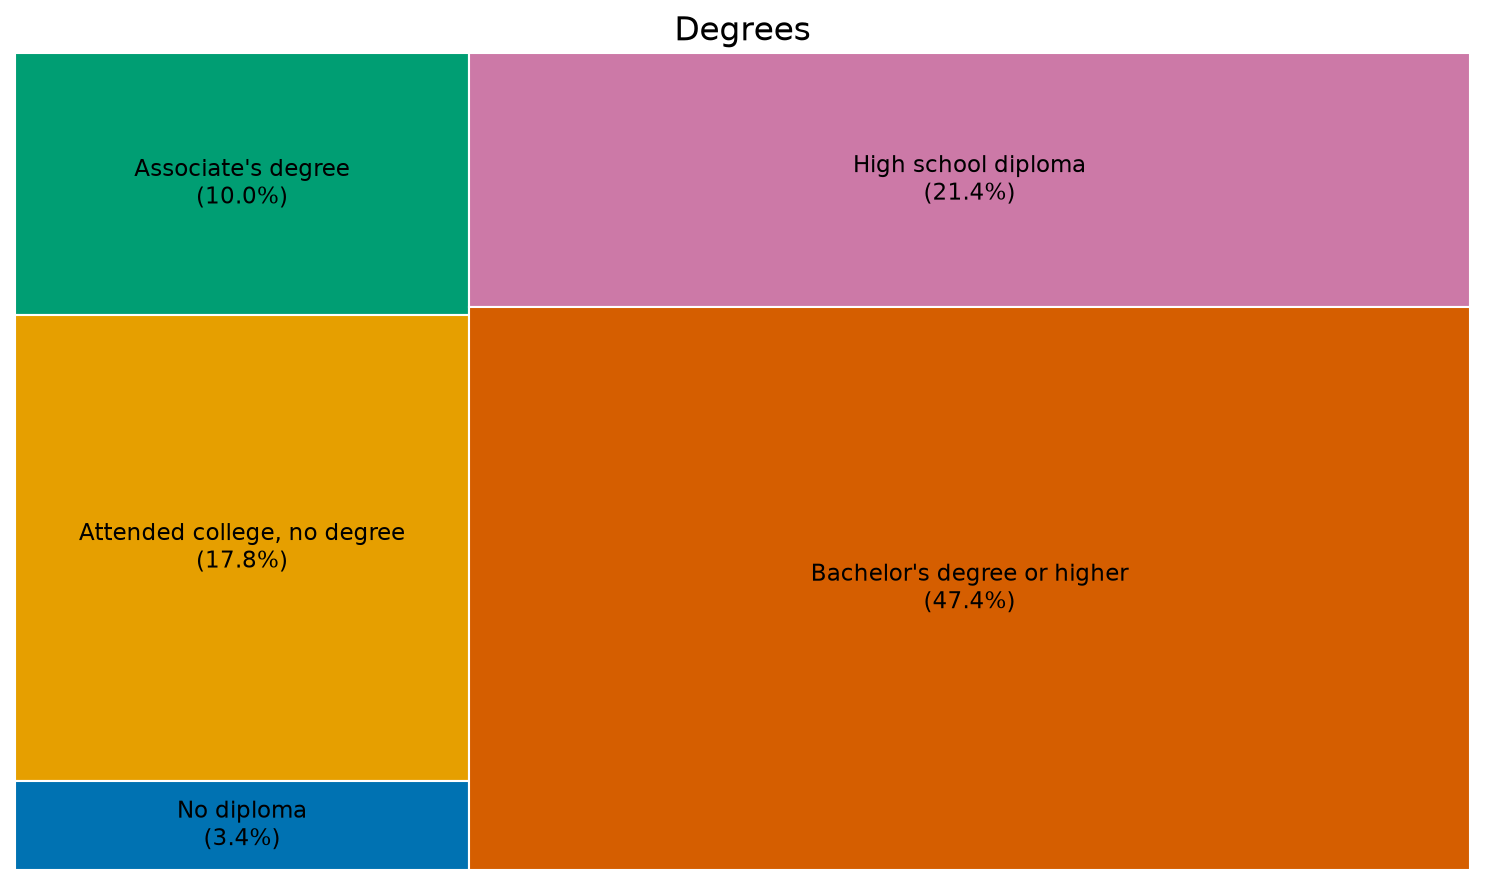

In [3]:
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# 读取数据
data = pd.read_csv("age_salary_hours.csv")

# 教育类别顺序
education_order = [
    "Associate's degree",
    "High school diploma",
    "Attended college, no degree",
    "Bachelor's degree or higher",
    "No diploma"
]

# 计算百分比
percentages = (
    data["Education"]
    .value_counts(normalize=True)
    .mul(100)
    .reindex(education_order)
    .fillna(0)
)

# 单独保存百分比，避免 f-string 引号冲突
associate_pct = percentages["Associate's degree"]
high_school_pct = percentages["High school diploma"]
college_pct = percentages["Attended college, no degree"]
bachelor_pct = percentages["Bachelor's degree or higher"]
no_diploma_pct = percentages["No diploma"]

# 颜色
colors = {
    "Associate's degree": "#009E73",
    "High school diploma": "#CC79A7",
    "Attended college, no degree": "#E69F00",
    "Bachelor's degree or higher": "#D55E00",
    "No diploma": "#0072B2"
}

# 左右两列总面积
left_total = (
    associate_pct
    + college_pct
    + no_diploma_pct
)

right_total = (
    high_school_pct
    + bachelor_pct
)

left_width = left_total / 100
right_width = right_total / 100

# 创建画布
fig, ax = plt.subplots(
    figsize=(10, 6),
    dpi=150
)

# Associate's degree
associate_height = associate_pct / left_total

ax.add_patch(
    Rectangle(
        (0, 1 - associate_height),
        left_width,
        associate_height,
        facecolor=colors["Associate's degree"],
        edgecolor="white",
        linewidth=1
    )
)

ax.text(
    left_width / 2,
    1 - associate_height / 2,
    f"Associate's degree\n({associate_pct:.1f}%)",
    ha="center",
    va="center",
    fontsize=11
)

# Attended college, no degree
college_height = college_pct / left_total

ax.add_patch(
    Rectangle(
        (0, 1 - associate_height - college_height),
        left_width,
        college_height,
        facecolor=colors["Attended college, no degree"],
        edgecolor="white",
        linewidth=1
    )
)

ax.text(
    left_width / 2,
    1 - associate_height - college_height / 2,
    f"Attended college, no degree\n({college_pct:.1f}%)",
    ha="center",
    va="center",
    fontsize=11
)

# No diploma
no_diploma_height = no_diploma_pct / left_total

ax.add_patch(
    Rectangle(
        (0, 0),
        left_width,
        no_diploma_height,
        facecolor=colors["No diploma"],
        edgecolor="white",
        linewidth=1
    )
)

ax.text(
    left_width / 2,
    no_diploma_height / 2,
    f"No diploma\n({no_diploma_pct:.1f}%)",
    ha="center",
    va="center",
    fontsize=11
)

# High school diploma
high_school_height = high_school_pct / right_total

ax.add_patch(
    Rectangle(
        (left_width, 1 - high_school_height),
        right_width,
        high_school_height,
        facecolor=colors["High school diploma"],
        edgecolor="white",
        linewidth=1
    )
)

ax.text(
    left_width + right_width / 2,
    1 - high_school_height / 2,
    f"High school diploma\n({high_school_pct:.1f}%)",
    ha="center",
    va="center",
    fontsize=11
)

# Bachelor's degree or higher
bachelor_height = bachelor_pct / right_total

ax.add_patch(
    Rectangle(
        (left_width, 0),
        right_width,
        bachelor_height,
        facecolor=colors["Bachelor's degree or higher"],
        edgecolor="white",
        linewidth=1
    )
)

ax.text(
    left_width + right_width / 2,
    bachelor_height / 2,
    f"Bachelor's degree or higher\n({bachelor_pct:.1f}%)",
    ha="center",
    va="center",
    fontsize=11
)

# 设置图形外观
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("Degrees", fontsize=16)

plt.tight_layout()
plt.show()

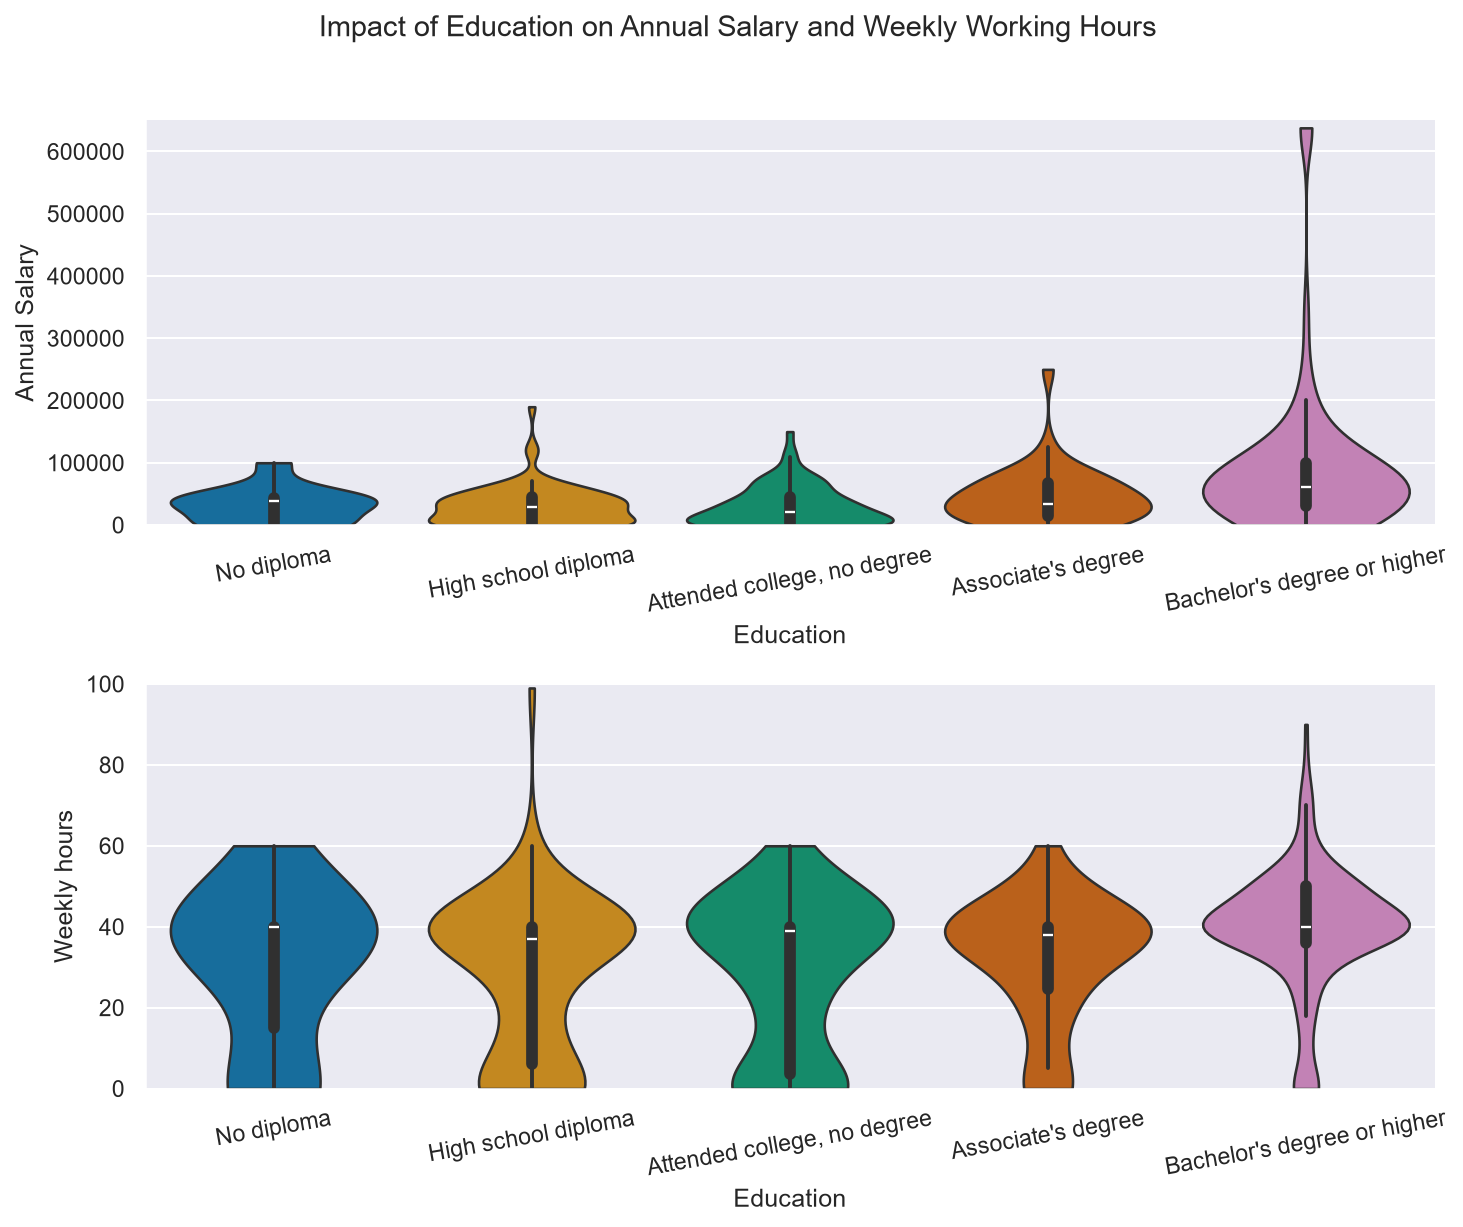

In [3]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="darkgrid",
    context="notebook"
)

# 读取数据
data = pd.read_csv("age_salary_hours.csv")

# 排除 65 岁及以上人员
working_data = data[
    data["Age"] < 65
].copy()

# 教育类别顺序
education_order = [
    "No diploma",
    "High school diploma",
    "Attended college, no degree",
    "Associate's degree",
    "Bachelor's degree or higher"
]

# 色盲友好配色
colorblind_palette = sns.color_palette(
    "colorblind",
    n_colors=len(education_order)
)

# 创建两个子图
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(10, 8),
    dpi=150
)

# 年收入 violin plot
sns.violinplot(
    data=working_data,
    x="Education",
    y="Annual Salary",
    hue="Education",
    order=education_order,
    hue_order=education_order,
    palette=colorblind_palette,
    inner="box",
    cut=0,
    legend=False,
    ax=axes[0]
)

axes[0].set_ylabel("Annual Salary")
axes[0].set_xlabel("Education")

# 设置年收入坐标范围
axes[0].set_ylim(
    0,
    650000
)

# 每周工作时间 violin plot
sns.violinplot(
    data=working_data,
    x="Education",
    y="Weekly hours",
    hue="Education",
    order=education_order,
    hue_order=education_order,
    palette=colorblind_palette,
    inner="box",
    cut=0,
    legend=False,
    ax=axes[1]
)

axes[1].set_ylabel("Weekly hours")
axes[1].set_xlabel("Education")

# 设置每周工作时间坐标范围
axes[1].set_ylim(
    0,
    100
)

# 设置总标题
fig.suptitle(
    "Impact of Education on Annual Salary and Weekly Working Hours",
    fontsize=14,
    y=1.02
)

# 旋转横轴标签
for ax in axes:
    ax.tick_params(
        axis="x",
        rotation=10
    )
    sns.despine(
        ax=ax,
        top=True,
        right=True
    )

plt.tight_layout()
plt.show()